# Part 2 — Trial-outcome classifier, error analysis by stopping reason, and improved model

**Task.** Predict P(label = 1) (trial met its primary endpoint) for Phase I, II and III trials. Kaggle scores the mean per-phase log loss.

**Models compared**

| Model | Description |
|---|---|
| Multinomial NB (per phase) | Bag-of-words + bigram counts of the eligibility criteria |
| **Baseline:** LR (per phase) | One logistic regression per phase on criteria TF-IDF (1–2 grams) |
| **Improved:** stacked ensemble | 8 base models, each on one field (criteria TF-IDF, diseases, ICD codes, drug names, drug targets/pathways/actions, metadata, criteria MNB, criteria kNN), trained on all phases with a phase indicator; their out-of-fold logits feed a logistic-regression meta-model with phase indicators |
| **Final:** recency-weighted stack | Same stack, but every training row is weighted by exp((start_year − latest year) / 3), so trials from the most recent years count most |

The improvement was motivated by the error analysis below: the criteria-only baseline mislabels many failed Phase III trials and trials with no recorded stopping reason as successful. Disease, ICD and drug fields add information about *what* is being tested. Pooling phases also helps Phase I, which has only ~1,000 training rows.

Recency weighting targets the gap between validation and Kaggle: success rates rise steeply with start year, and the test trials are later than every training trial. It was chosen on time-based holdouts, not on the leaderboard.

Reason embeddings and reason labels are used **only** for the error analysis, never as inputs.

In [1]:
import ast
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import normalize
from sklearn.metrics import log_loss, roc_auc_score, average_precision_score, f1_score

DATA = '../part2/'
PHASES = ['I', 'II', 'III']
REASONS = ['Safety', 'Funding', 'Efficacy', 'Recruitment', 'Other']

train = pd.read_csv(DATA + 'outcome_train.csv')
val = pd.read_csv(DATA + 'outcome_val.csv')
test = pd.read_csv(DATA + 'outcome_test.csv')
df = pd.concat([train.assign(split='train'), val.assign(split='val'), test.assign(split='test')], ignore_index=True)
i_tr, i_va, i_te = (np.flatnonzero(df.split == s) for s in ['train', 'val', 'test'])
y, phase, groups = df.label.values, df.phase.values, df.trial_id.values

print(f'train {len(i_tr)}, val {len(i_va)}, test {len(i_te)}')
display(df.iloc[np.r_[i_tr, i_va]].groupby(['split', 'phase']).label.agg(['count', 'mean']).round(3).unstack(0))
print('success rate by start year (train):')
train.groupby('start_year').label.mean().loc[2000:].round(2).to_frame().T

train 8037, val 1013, test 1500


count        mean       
split train  val  train    val
phase                         
I      1012  149  0.566  0.570
II     3950  501  0.477  0.471
III    3075  363  0.653  0.661

success rate by start year (train):


start_year,2000.0,2001.0,2002.0,2003.0,2004.0,2005.0,2006.0,2007.0,2008.0,2009.0,2010.0,2011.0,2012.0,2013.0
label,0.38,0.42,0.32,0.41,0.47,0.5,0.57,0.58,0.58,0.54,0.62,0.65,0.7,0.81


Success rate rises steadily with start year, and the test trials (2014–2021) are later than any training trial. A model that only learned the training base rate would be under-confident on test. The time-based holdout below checks how well each model carries over to later years.

## Features

In [2]:
def parse_list(s):
    try:
        out = []
        for x in ast.literal_eval(s):
            out += ast.literal_eval(x) if isinstance(x, str) and x.startswith('[') else [x]
        return [str(x) for x in out]
    except (ValueError, SyntaxError):
        return []


def semicolon_tokens(col):
    return df[col].fillna('').map(lambda s: ' '.join(sorted({t.strip() for t in s.split(';') if t.strip()})))


icd = df.icdcodes.fillna('[]').map(parse_list)
text = {
    'criteria': df.criteria.fillna(''),
    'disease': df.diseases_cleaned.fillna('[]').map(lambda s: ' '.join(parse_list(s))),
    'drug': df.drugs.fillna('[]').map(lambda s: ' '.join(parse_list(s))),
    # ICD codes at three granularities: chapter letter, 3-char category, 5-char subcategory
    'icd': icd.map(lambda L: ' '.join(sorted({c[:1] for c in L} | {c[:3] for c in L} | {c[:5] for c in L}))),
    'targets': semicolon_tokens('drug_targets'),
    'pathways': semicolon_tokens('drug_pathways'),
    'actions': semicolon_tokens('drug_actions'),
}
split_tokens = dict(tokenizer=str.split, lowercase=False, token_pattern=None)

F = {
    'criteria': TfidfVectorizer(min_df=5, ngram_range=(1, 2), sublinear_tf=True).fit_transform(text['criteria']),
    'crit_counts': CountVectorizer(min_df=5, ngram_range=(1, 2)).fit_transform(text['criteria']),
    'disease': TfidfVectorizer(min_df=2, ngram_range=(1, 2), sublinear_tf=True).fit_transform(text['disease']),
    'drug': TfidfVectorizer(min_df=2, sublinear_tf=True).fit_transform(text['drug']),
    'icd': TfidfVectorizer(min_df=2, **split_tokens).fit_transform(text['icd']),
    'targets': TfidfVectorizer(min_df=3, **split_tokens).fit_transform(text['targets']),
    'pathways': TfidfVectorizer(min_df=5, **split_tokens).fit_transform(text['pathways']),
    'actions': CountVectorizer(min_df=2, binary=True, **split_tokens).fit_transform(text['actions']),
    'meta': sp.csr_matrix(np.column_stack([
        df.matched_drugs.notna(), np.log1p(text['drug'].str.split().str.len()), np.log1p(text['criteria'].str.len()) / 10,
        df.phase_detail.str.contains('/'), df.phase_detail.eq('early phase 1')]).astype(float)),
}
PHASE_1HOT = sp.csr_matrix(pd.get_dummies(df.phase)[PHASES].values.astype(float))
CRIT_NORM = normalize(F['criteria'])
pd.Series({k: v.shape[1] for k, v in F.items()}, name='n_features').to_frame().T

,criteria,crit_counts,disease,drug,icd,targets,pathways,actions,meta
n_features,78254,78254,3909,3009,2382,804,1795,31,5


## Models

In [3]:
def per_phase(fit, pred, make_model, X):
    p = np.zeros(len(pred))
    for ph in PHASES:
        a, b = fit[phase[fit] == ph], phase[pred] == ph
        p[b] = make_model().fit(X[a], y[a]).predict_proba(X[pred[b]])[:, 1]
    return p


def nb_per_phase(fit, pred):
    return per_phase(fit, pred, lambda: MultinomialNB(alpha=1.0), F['crit_counts'])


def baseline_lr(fit, pred):
    return per_phase(fit, pred, lambda: LogisticRegression(C=1.0, max_iter=3000), F['criteria'])


def pooled_lr(blocks, C):
    X = sp.hstack([F[b] for b in blocks] + [PHASE_1HOT]).tocsr()
    return lambda fit, pred, w=None: (LogisticRegression(C=C, max_iter=3000).fit(X[fit], y[fit], sample_weight=w)
                                      .predict_proba(X[pred])[:, 1])


def pooled_nb(fit, pred, w=None):
    X = sp.hstack([F['crit_counts'], PHASE_1HOT]).tocsr()
    return MultinomialNB(alpha=1.0).fit(X[fit], y[fit], sample_weight=w).predict_proba(X[pred])[:, 1]


def knn_criteria(fit, pred, w=None, k=50):
    p = np.zeros(len(pred))
    for ph in PHASES:
        a, b = fit[phase[fit] == ph], pred[phase[pred] == ph]
        S = (CRIT_NORM[b] @ CRIT_NORM[a].T).toarray()
        idx = np.argpartition(-S, k, axis=1)[:, :k]
        w = np.take_along_axis(S, idx, 1)
        p[phase[pred] == ph] = ((w * y[a][idx]).sum(1) + 1) / (w.sum(1) + 2)
    return p


BASE_MODELS = {
    'criteria LR': pooled_lr(['criteria'], 2.0),
    'disease LR': pooled_lr(['disease'], 1.0),
    'ICD LR': pooled_lr(['icd'], 1.0),
    'drug-name LR': pooled_lr(['drug'], 1.0),
    'drug-knowledge LR': pooled_lr(['targets', 'pathways', 'actions'], 0.3),
    'metadata LR': pooled_lr(['meta'], 1.0),
    'criteria MNB': pooled_nb,
    'criteria kNN': knn_criteria,
}


def logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))


year = df.start_year.fillna(df.start_year.median()).values


def stacked(fit, pred, tau=None, phase3_year=False, return_meta=False):
    w = np.ones(len(fit)) if tau is None else np.exp((year[fit] - year[fit].max()) / tau)
    w = w / w.mean()
    Z_fit, Z_pred = np.zeros((len(fit), len(BASE_MODELS))), np.zeros((len(pred), len(BASE_MODELS)))
    for j, fn in enumerate(BASE_MODELS.values()):
        for a, b in GroupKFold(5).split(fit, groups=groups[fit]):
            Z_fit[b, j] = fn(fit[a], fit[b], w[a])
        Z_pred[:, j] = fn(fit, pred, w)

    def meta_X(Z, idx):
        ph = pd.get_dummies(pd.Categorical(phase[idx], PHASES)).values.astype(float)
        cols = [logit(Z), ph]
        if phase3_year:
            # capped 2 years past the last training year so the trend is not extrapolated to 2021
            cols.append((ph[:, 2] * (np.minimum(year[idx], year[fit].max() + 2) - 2007) / 3)[:, None])
        return np.hstack(cols)

    meta = LogisticRegression(C=1.0, max_iter=3000).fit(meta_X(Z_fit, fit), y[fit], sample_weight=w)
    p = meta.predict_proba(meta_X(Z_pred, pred))[:, 1]
    return (p, meta, Z_pred) if return_meta else p


MODELS = {'Multinomial NB (per phase)': nb_per_phase, 'Baseline LR (per phase)': baseline_lr,
          'Improved: stacked ensemble': stacked,
          'Final: recency-weighted stack (tau=3)': lambda fit, pred: stacked(fit, pred, tau=3)}

## Validation results (trained on `outcome_train.csv`, evaluated on `outcome_val.csv`)

F1 uses a 0.5 threshold; ROC-AUC, PR-AUC and log loss use the predicted probabilities.

In [4]:
def phase_metrics(idx, p):
    rows = {}
    for ph in PHASES:
        m = phase[idx] == ph
        yt, pp = y[idx][m], p[m]
        rows[ph] = {'F1': f1_score(yt, pp >= 0.5), 'ROC-AUC': roc_auc_score(yt, pp),
                    'PR-AUC': average_precision_score(yt, pp), 'log loss': log_loss(yt, np.clip(pp, 1e-4, 1 - 1e-4))}
    out = pd.DataFrame(rows).T
    out.loc['mean'] = out.mean()
    return out


val_pred = {name: fn(i_tr, i_va) for name, fn in MODELS.items()}
val_table = pd.concat({name: phase_metrics(i_va, p) for name, p in val_pred.items()}, names=['model', 'phase'])
val_table.round(3)

F1  ROC-AUC  PR-AUC  log loss
model                                 phase                                  
Multinomial NB (per phase)            I      0.737    0.717   0.733     2.684
                                      II     0.645    0.694   0.623     2.945
                                      III    0.796    0.699   0.783     2.308
                                      mean   0.726    0.703   0.713     2.646
Baseline LR (per phase)               I      0.774    0.780   0.809     0.609
                                      II     0.631    0.729   0.711     0.610
                                      III    0.813    0.764   0.868     0.553
                                      mean   0.739    0.758   0.796     0.591
Improved: stacked ensemble            I      0.730    0.772   0.816     0.570
                                      II     0.661    0.749   0.733     0.591
                                      III    0.817    0.787   0.883     0.516
                                      mean   0.736    0.769   0.810     0.559
Final: recency-weighted stack (tau=3) I      0.793    0.793   0.828     0.557
                                      II     0.648    0.754   0.735     0.593
                                      III    0.824    0.787   0.881     0.518
                                      mean   0.755    0.778   0.814     0.556

### Time-based holdout

This fits on train + val trials that started up to 2009 and evaluates on trials from 2010–2013. It mimics the later start years of the test set. A second, harder holdout fits on trials up to 2011 and evaluates on 2012–2013.

In [5]:
i_all = np.r_[i_tr, i_va]
temporal = {}
for cut in [2009, 2011]:
    t_fit, t_eval = i_all[year[i_all] <= cut], i_all[year[i_all] > cut]
    print(f'<= {cut}: fit n={len(t_fit)} (success rate {y[t_fit].mean():.3f}), '
          f'eval n={len(t_eval)} (success rate {y[t_eval].mean():.3f})')
    temporal[f'fit <= {cut}'] = pd.DataFrame({name: phase_metrics(t_eval, fn(t_fit, t_eval)).loc['mean']
                                              for name, fn in MODELS.items()}).T
pd.concat(temporal, names=['holdout', 'model']).round(4)

<= 2009: fit n=6760 (success rate 0.522), eval n=2290 (success rate 0.655)


<= 2011: fit n=8565 (success rate 0.546), eval n=485 (success rate 0.728)


F1  ROC-AUC  PR-AUC  \
holdout     model                                                            
fit <= 2009 Multinomial NB (per phase)             0.8083   0.6295  0.7301   
            Baseline LR (per phase)                0.8051   0.6943  0.7847   
            Improved: stacked ensemble             0.8090   0.7248  0.8183   
            Final: recency-weighted stack (tau=3)  0.8094   0.7311  0.8205   
fit <= 2011 Multinomial NB (per phase)             0.8576   0.5970  0.7740   
            Baseline LR (per phase)                0.8654   0.7042  0.8290   
            Improved: stacked ensemble             0.8697   0.7539  0.8850   
            Final: recency-weighted stack (tau=3)  0.8758   0.7604  0.8865   

                                                   log loss  
holdout     model                                            
fit <= 2009 Multinomial NB (per phase)               2.4794  
            Baseline LR (per phase)                  0.5879  
            Improved: stacked ensemble               0.5514  
            Final: recency-weighted stack (tau=3)    0.5475  
fit <= 2011 Multinomial NB (per phase)               2.0120  
            Baseline LR (per phase)                  0.5192  
            Improved: stacked ensemble               0.4657  
            Final: recency-weighted stack (tau=3)    0.4553

## Error analysis by stopping reason (validation set, label = 0 only)

Each failed validation trial is matched to Part 1 by `trial_id`. Reason labels are **true** labels for the 157 labeled Part 1 training trials and all Part 1 validation trials. They are **predicted** by the Part 1 model for the other Part 1 training trials and the Part 1 test trials. Failed trials not in Part 1 ran to completion and form the "No recorded reason" group. A trial with several reasons counts toward each of them. Each phase is analyzed separately, so a combined-phase trial is counted once per phase.

The error rate is the fraction of failed trials predicted as successful (P ≥ 0.5).

In [6]:
reasons = pd.read_csv('part1_best_reason_labels.csv').set_index('ID')[REASONS + ['source']]
failed = df.iloc[i_va].assign(**{n: p for n, p in val_pred.items()})
failed = failed[failed.label == 0].join(reasons, on='trial_id')
print(f'failed val rows: {len(failed)} | matched to Part 1: {failed.source.notna().sum()} '
      f"({(failed.source == 'true').sum()} true labels, {(failed.source == 'predicted').sum()} predicted)")

rows = []
for ph in PHASES:
    g = failed[failed.phase == ph]
    groups_by_reason = {r: g[g[r] == 1] for r in REASONS} | {'No recorded reason': g[g.source.isna()]}
    for reason, s in groups_by_reason.items():
        rows.append({'phase': ph, 'reason': reason, 'n trials': len(s),
                     'n true labels': int((s.source == 'true').sum()), 'n predicted labels': int((s.source == 'predicted').sum()),
                     **{f'error: {n.split(":")[0].split(" (")[0]}': (s[n] >= 0.5).mean() if len(s) else np.nan
                        for n in ['Baseline LR (per phase)', 'Improved: stacked ensemble', 'Final: recency-weighted stack (tau=3)']}})
errors = pd.DataFrame(rows).set_index(['phase', 'reason'])
errors.round(3)

failed val rows: 452 | matched to Part 1: 198 (27 true labels, 171 predicted)


n trials  n true labels  n predicted labels  \
phase reason                                                            
I     Safety                     8              1                   7   
      Funding                    3              1                   2   
      Efficacy                   1              0                   1   
      Recruitment               23              2                  21   
      Other                      3              0                   3   
      No recorded reason        28              0                   0   
II    Safety                    12              1                  11   
      Funding                    4              1                   3   
      Efficacy                   7              0                   7   
      Recruitment               87             12                  75   
      Other                     20              3                  17   
      No recorded reason       144              0                   0   
III   Safety                     7              1                   6   
      Funding                    0              0                   0   
      Efficacy                   8              0                   8   
      Recruitment               22              5                  17   
      Other                      9              2                   7   
      No recorded reason        82              0                   0   

                          error: Baseline LR  error: Improved  error: Final  
phase reason                                                                 
I     Safety                           0.500            0.500         0.375  
      Funding                          0.667            0.333         0.000  
      Efficacy                         1.000            1.000         0.000  
      Recruitment                      0.522            0.391         0.174  
      Other                            0.667            0.667         0.667  
      No recorded reason               0.643            0.464         0.321  
II    Safety                           0.333            0.333         0.250  
      Funding                          0.000            0.000         0.000  
      Efficacy                         0.286            0.286         0.286  
      Recruitment                      0.207            0.207         0.149  
      Other                            0.250            0.250         0.250  
      No recorded reason               0.382            0.306         0.250  
III   Safety                           0.571            0.429         0.429  
      Funding                            NaN              NaN           NaN  
      Efficacy                         1.000            0.875         1.000  
      Recruitment                      0.682            0.545         0.455  
      Other                            0.778            0.667         0.556  
      No recorded reason               0.695            0.561         0.585

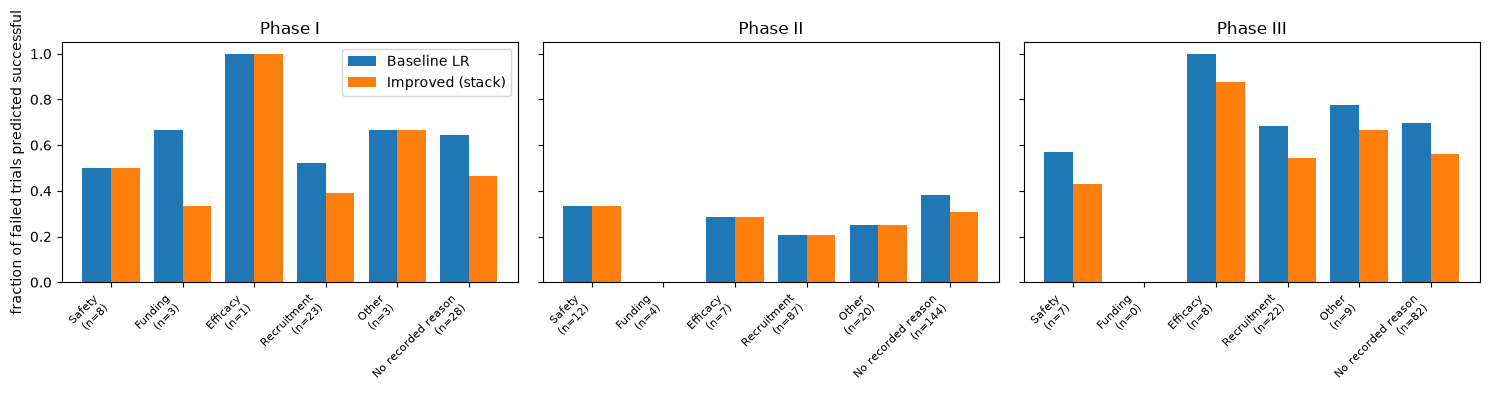

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, ph in zip(axes, PHASES):
    e = errors.loc[ph]
    x = np.arange(len(e))
    ax.bar(x - 0.2, e['error: Baseline LR'], 0.4, label='Baseline LR')
    ax.bar(x + 0.2, e['error: Improved'], 0.4, label='Improved (stack)')
    ax.set_xticks(x, [f'{r}\n(n={n})' for r, n in zip(e.index, e['n trials'])], rotation=45, ha='right', fontsize=8)
    ax.set_title(f'Phase {ph}')
axes[0].set_ylabel('fraction of failed trials predicted successful')
axes[0].legend()
plt.tight_layout()
plt.savefig('part2_error_by_reason.png', dpi=150)

**Reading the table:** category sizes are small. Funding, Efficacy, Safety and Other have under 25 failed trials per phase, so their error rates are noisy. Most of their reason labels are Part 1 predictions, which carry roughly 10% label error (Part 1 val sample-F1 ≈ 0.89). The large groups (Phase II Recruitment and the No-recorded-reason groups) are the most reliable comparisons.

## Final model: refit on train + val and predict the test set

The submission is the recency-weighted stack (τ = 3). An alternative, `part2_alt_phase3_trend_submission.csv`, also lets the meta-model learn a Phase III year trend, capped at 2015. Phase III success rises from 0.71 (2009) to 0.96 (2013). On the holdouts this helps only slightly (≈0.001 log loss), but it raises test Phase III predictions noticeably, so it is the riskier option. A per-phase year trend for all phases was rejected: it extrapolates flat or negative Phase I/II slopes and lowers their test predictions below the training rate.

In [8]:
p_test, meta, Z_test = stacked(i_all, i_te, tau=3, return_meta=True)
submission = pd.DataFrame({'ID': df.ID.values[i_te], 'label': np.clip(p_test, 1e-3, 1 - 1e-3)})
submission.to_csv('part2_best_submission.csv', index=False)

p_alt = stacked(i_all, i_te, tau=3, phase3_year=True)
pd.DataFrame({'ID': df.ID.values[i_te], 'label': np.clip(p_alt, 1e-3, 1 - 1e-3)}).to_csv(
    'part2_alt_phase3_trend_submission.csv', index=False)
p_unweighted = stacked(i_all, i_te)

print('meta-model weights:', dict(zip(list(BASE_MODELS) + PHASES, meta.coef_[0].round(2))))
pd.DataFrame({'train+val success rate': pd.Series(y[i_all]).groupby(phase[i_all]).mean(),
              'test mean: unweighted stack': pd.Series(p_unweighted).groupby(phase[i_te]).mean(),
              'test mean: final (tau=3)': submission.groupby(phase[i_te]).label.mean(),
              'test mean: alt (+ Phase III trend)': pd.Series(p_alt).groupby(phase[i_te]).mean()}).round(3)

meta-model weights: {'criteria LR': np.float64(0.62), 'disease LR': np.float64(0.06), 'ICD LR': np.float64(0.03), 'drug-name LR': np.float64(0.41), 'drug-knowledge LR': np.float64(-0.11), 'metadata LR': np.float64(0.16), 'criteria MNB': np.float64(-0.01), 'criteria kNN': np.float64(0.55), 'I': np.float64(-0.06), 'II': np.float64(0.14), 'III': np.float64(-0.3)}


,train+val success rate,test mean: unweighted stack,test mean: final (tau=3),test mean: alt (+ Phase III trend)
I,0.567,0.617,0.598,0.598
II,0.476,0.565,0.557,0.556
III,0.654,0.711,0.738,0.788
